Cell 1 — Environment Setup & Data Loading

In [4]:
# Required packages for the added models and SHAP analysis.
# %pip install -q xgboost lightgbm catboost shap

# Cell 1 — Dataset Loading

# প্রয়োজনে:
# %pip install pandas numpy scikit-learn lightgbm psutil matplotlib seaborn

import os

os.environ["OMP_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"

import gc
import time
import tracemalloc
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import psutil
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# একবারে একটি dataset চালান
DATASET_NAME = "mqtt"       # "mqtt" অথবা "edgeiiot"

# Publication experiment
USE_SAMPLE = False

# দ্রুত test করতে চাইলে True করুন
# USE_SAMPLE = True
MAX_ROWS_PER_FILE = 5_000
MAX_TOTAL_ROWS = 30_000

DATASET_PATHS = {
    "mqtt": Path(
        "/kaggle/input/datasets/ogunyemioluwapelumi/"
        "mqtt-iot-ids2020-private"
    ),
    "edgeiiot": Path(
        "/kaggle/input/datasets/mohamedamineferrag/"
        "edgeiiotset-cyber-security-dataset-of-iot-iiot"
    )
}

if DATASET_NAME not in DATASET_PATHS:
    raise ValueError(
        "DATASET_NAME অবশ্যই 'mqtt' অথবা 'edgeiiot' হতে হবে।"
    )


def normalize_columns(data):
    data = data.copy()

    data.columns = (
        data.columns
        .astype(str)
        .str.strip()
        .str.replace(r"[^A-Za-z0-9_]+", "_", regex=True)
        .str.strip("_")
    )

    return data


def detect_target_column(data):
    """
    Multi-class attack target-কে অগ্রাধিকার দেওয়া হয়।
    প্রয়োজন হলে TARGET_COLUMN manually set করুন।
    """

    preferred_targets = [
        "attack_type",
        "attack_category",
        "attack_cat",
        "category",
        "attack",
        "label",
        "class",
        "target",
        "is_attack",
        "binary_label"
    ]

    lookup = {
        column.lower(): column
        for column in data.columns
    }

    # প্রথমে multi-class target খোঁজা
    for target_name in preferred_targets:

        if target_name.lower() not in lookup:
            continue

        candidate = lookup[target_name.lower()]
        unique_count = data[candidate].nunique(dropna=True)

        if target_name.lower() in {
            "is_attack",
            "binary_label"
        }:
            continue

        if unique_count >= 3:
            return candidate

    # Keyword-based multi-class matching
    candidates = []

    for column in data.columns:
        column_lower = column.lower()
        unique_count = data[column].nunique(dropna=True)

        if (
            unique_count >= 3
            and any(
                keyword in column_lower
                for keyword in [
                    "attack_type",
                    "attack_category",
                    "attack_cat",
                    "category",
                    "attack"
                ]
            )
        ):
            candidates.append(column)

    if candidates:
        return candidates[0]

    # General multiclass target
    for target_name in ["label", "class", "target"]:

        if target_name in lookup:

            candidate = lookup[target_name]

            if data[candidate].nunique(dropna=True) >= 3:
                return candidate

    # Binary fallback
    for target_name in ["is_attack", "binary_label"]:

        if target_name in lookup:
            print(
                "WARNING: Multi-class target পাওয়া যায়নি। "
                f"Binary target ব্যবহার হচ্ছে: {lookup[target_name]}"
            )
            return lookup[target_name]

    raise ValueError(
        "Target column শনাক্ত করা যায়নি.\n"
        f"Available columns: {data.columns.tolist()}"
    )


def load_dataset(dataset_name):
    dataset_dir = DATASET_PATHS[dataset_name]
    csv_files = sorted(dataset_dir.rglob("*.csv"))

    if not csv_files:
        raise FileNotFoundError(
            f"No CSV files found: {dataset_dir}"
        )

    print(f"{len(csv_files)}টি CSV file পাওয়া গেছে।")

    frames = []
    total_rows = 0

    for file_number, file_path in enumerate(csv_files, start=1):

        if USE_SAMPLE:

            remaining_rows = (
                MAX_TOTAL_ROWS - total_rows
            )

            if remaining_rows <= 0:
                break

            rows_to_read = min(
                MAX_ROWS_PER_FILE,
                remaining_rows
            )

        else:
            rows_to_read = None

        try:
            current_df = pd.read_csv(
                file_path,
                nrows=rows_to_read,
                low_memory=False
            )

            if current_df.empty:
                continue

            frames.append(current_df)
            total_rows += len(current_df)

            print(
                f"[{file_number}/{len(csv_files)}] "
                f"{file_path.name}: {len(current_df):,} rows"
            )

        except Exception as error:
            print(
                f"Skipped {file_path.name}: {error}"
            )

    if not frames:
        raise ValueError(
            "কোনো CSV সফলভাবে load করা যায়নি।"
        )

    data = pd.concat(
        frames,
        ignore_index=True,
        sort=False
    )

    del frames
    gc.collect()

    data = normalize_columns(data)

    # চাইলে exact target column এখানে লিখুন
    TARGET_COLUMN = None

    if TARGET_COLUMN is None:
        TARGET_COLUMN = detect_target_column(data)

    print(f"\nSelected target column: {TARGET_COLUMN}")

    data = data.replace(
        [np.inf, -np.inf],
        np.nan
    )

    data = data.drop_duplicates()
    data = data.dropna(
        subset=[TARGET_COLUMN]
    )

    data = data.reset_index(drop=True)

    # Identifier এবং leakage-prone columns বাদ
    identifier_keywords = [
        "ip",
        "port",
        "prt",
        "mac",
        "flow_id",
        "flowid",
        "session_id",
        "sessionid",
        "device_id",
        "deviceid",
        "timestamp",
        "time_stamp",
        "date",
        "filename",
        "source_file"
    ]

    columns_to_drop = [
        column
        for column in data.columns
        if (
            column == TARGET_COLUMN
            or any(
                keyword in column.lower()
                for keyword in identifier_keywords
            )
        )
    ]

    print("\nDropped identifier columns:")
    print(columns_to_drop)

    X = data.drop(
        columns=columns_to_drop,
        errors="ignore"
    ).copy()

    y_text = data[TARGET_COLUMN].astype(str)

    del data
    gc.collect()

    # Numeric columns remain numeric.
    # Categorical columns remain object/category and are
    # encoded inside the CV pipeline in Cell 2.
    for column in X.select_dtypes(
        include=["bool"]
    ).columns:
        X[column] = X[column].astype(str)

    # Remove all-missing columns
    X = X.dropna(
        axis=1,
        how="all"
    )

    # Remove constant columns without fitting any scaler
    non_constant_columns = [
        column
        for column in X.columns
        if X[column].nunique(dropna=False) > 1
    ]

    X = X[non_constant_columns]

    # Encode target only
    target_encoder = LabelEncoder()

    y = pd.Series(
        target_encoder.fit_transform(y_text),
        name="target",
        dtype=np.int64
    )

    del y_text
    gc.collect()

    print("\nDataset summary:")
    print(f"Dataset: {dataset_name}")
    print(f"Rows: {len(X):,}")
    print(f"Features: {X.shape[1]}")
    print(f"Classes: {y.nunique()}")
    print(f"Target: {TARGET_COLUMN}")

    print("\nClass distribution:")
    display(
        y.value_counts()
        .sort_index()
        .rename("count")
        .to_frame()
    )

    print("\nClass mapping:")
    for index, label in enumerate(
        target_encoder.classes_
    ):
        print(f"{index}: {label}")

    if y.nunique() <= 2:
        print(
            "\nWARNING: Target binary. "
            "Publication-এর জন্য attack-type target ব্যবহার করুন।"
        )

    return (
        X.reset_index(drop=True),
        y.reset_index(drop=True),
        target_encoder,
        TARGET_COLUMN
    )


X, y, target_encoder, TARGET_COLUMN = load_dataset(
    DATASET_NAME
)

5টি CSV file পাওয়া গেছে।
[1/5] biflow_mqtt_bruteforce.csv: 16,696 rows
[2/5] biflow_normal.csv: 86,008 rows
[3/5] biflow_scan_A.csv: 25,693 rows
[4/5] biflow_scan_sU.csv: 39,664 rows
[5/5] biflow_sparta.csv: 91,318 rows

Selected target column: is_attack

Dropped identifier columns:
['ip_src', 'ip_dst', 'prt_src', 'prt_dst', 'is_attack']

Dataset summary:
Dataset: mqtt
Rows: 259,190
Features: 26
Classes: 2
Target: is_attack

Class distribution:


,count
target,
0,188189
1,71001



Class mapping:
0: 0
1: 1



Cell 2 — Feature Selection Using ExtraTreesClassifier

In [5]:
# Cell 2 — Leakage-Free Pipeline and Models

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    ExtraTreesClassifier,
    RandomForestClassifier
)
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# Optional ablation
DROP_TOP_FEATURES = True

FEATURES_TO_REMOVE = [
    "fwd_std_pkt_len",
    "bwd_num_psh_flags"
]

if DROP_TOP_FEATURES:

    existing_features = [
        feature
        for feature in FEATURES_TO_REMOVE
        if feature in X.columns
    ]

    X = X.drop(
        columns=existing_features,
        errors="ignore"
    )

    print("Ablated features:")
    print(existing_features)

# Detect feature types
numeric_features = X.select_dtypes(
    include=[np.number]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print(f"Numeric features: {len(numeric_features)}")
print(f"Categorical features: {len(categorical_features)}")


def create_preprocessor():
    """
    This entire preprocessing object is fitted inside each CV fold.
    """

    transformers = []

    if numeric_features:

        numeric_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(strategy="median")
            ),
            (
                "scaler",
                StandardScaler()
            )
        ])

        transformers.append(
            (
                "numeric",
                numeric_pipeline,
                numeric_features
            )
        )

    if categorical_features:

        categorical_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                    dtype=np.float32
                )
            )
        ])

        transformers.append(
            (
                "categorical",
                categorical_pipeline,
                categorical_features
            )
        )

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        verbose_feature_names_out=False
    )


TOP_K = min(10, X.shape[1])

FAST_MODE = False

SELECTOR_TREES = (
    100 if not FAST_MODE else 20
)

MODEL_TREES = (
    100 if not FAST_MODE else 40
)


def create_feature_selector():
    """
    Fitted only on training data within each CV fold.
    """

    return SelectFromModel(
        estimator=ExtraTreesClassifier(
            n_estimators=SELECTOR_TREES,
            class_weight="balanced",
            n_jobs=2,
            random_state=RANDOM_STATE
        ),
        threshold=-np.inf,
        max_features=TOP_K
    )


def create_pipeline(model):
    """
    No preprocessing is fitted before CV.
    """

    return Pipeline([
        (
            "preprocessor",
            create_preprocessor()
        ),
        (
            "feature_selector",
            create_feature_selector()
        ),
        (
            "classifier",
            model
        )
    ])


models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=MODEL_TREES,
        max_depth=12,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=2,
        random_state=RANDOM_STATE
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=MODEL_TREES,
        max_depth=12,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=2,
        random_state=RANDOM_STATE
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=100,
        max_depth=8,
        num_leaves=31,
        learning_rate=0.05,
        min_child_samples=20,
        class_weight="balanced",
        n_jobs=2,
        verbosity=-1,
        random_state=RANDOM_STATE
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary:logistic" if y.nunique() == 2 else "multi:softprob",
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=2,
        random_state=RANDOM_STATE
    ),

    "CatBoost": CatBoostClassifier(
        iterations=100,
        depth=8,
        learning_rate=0.05,
        loss_function="Logloss" if y.nunique() == 2 else "MultiClass",
        verbose=False,
        random_seed=RANDOM_STATE,
        thread_count=2
    ),

    "MLP Neural Network": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=200,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=15,
        random_state=RANDOM_STATE
    )
}

if y.nunique() > 2:
    models["XGBoost"].set_params(num_class=y.nunique())

print(f"Feature count before encoding: {X.shape[1]}")
print(f"Top features selected after encoding: {TOP_K}")
print(f"FAST_MODE: {FAST_MODE}")

Ablated features:
['fwd_std_pkt_len', 'bwd_num_psh_flags']
Numeric features: 24
Categorical features: 0
Feature count before encoding: 24
Top features selected after encoding: 10
FAST_MODE: False


Cell 3 — 5-Fold Cross-Validation and Benchmarking

In [6]:
# Cell 3 — 10-Fold Stratified Evaluation

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)
from sklearn.preprocessing import label_binarize

N_SPLITS = 10

minimum_class_count = y.value_counts().min()

if minimum_class_count < N_SPLITS:
    raise ValueError(
        f"প্রতিটি class-এ কমপক্ষে {N_SPLITS}টি sample দরকার। "
        f"Smallest class contains {minimum_class_count} samples."
    )

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

fold_results = []
summary_results = []

classification_reports = {}
confusion_matrices = {}

number_of_classes = len(
    target_encoder.classes_
)

# Single-sample latency measurement
LATENCY_SAMPLES = 100

for model_name, base_model in models.items():

    print("\n" + "=" * 80)
    print(f"Running model: {model_name}")
    print("=" * 80)

    model_fold_results = []

    oof_predictions = np.full(
        len(y),
        -1,
        dtype=np.int64
    )

    oof_probabilities = np.zeros(
        (
            len(y),
            number_of_classes
        ),
        dtype=np.float32
    )

    for fold_number, (
        train_indices,
        test_indices
    ) in enumerate(
        cv.split(X, y),
        start=1
    ):

        X_train = X.iloc[train_indices]
        X_test = X.iloc[test_indices]

        y_train = y.iloc[train_indices]
        y_test = y.iloc[test_indices]

        pipeline = create_pipeline(
            clone(base_model)
        )

        # tracemalloc peak-memory tracking
        tracemalloc.start()
        tracemalloc.reset_peak()

        train_start = time.perf_counter()

        pipeline.fit(
            X_train,
            y_train
        )

        training_time = (
            time.perf_counter()
            - train_start
        )

        # Warm-up runs
        warmup_count = min(
            2,
            len(X_test)
        )

        for warmup_index in range(warmup_count):
            pipeline.predict(
                X_test.iloc[
                    warmup_index:warmup_index + 1
                ]
            )

        # Single-sample latency
        latency_count = min(
            LATENCY_SAMPLES,
            len(X_test)
        )

        latency_start = time.perf_counter()

        for sample_index in range(latency_count):

            pipeline.predict(
                X_test.iloc[
                    sample_index:sample_index + 1
                ]
            )

        latency_total = (
            time.perf_counter()
            - latency_start
        )

        latency_ms_per_sample = (
            latency_total
            / latency_count
        ) * 1000

        # Peak memory after training and inference
        _, peak_bytes = (
            tracemalloc.get_traced_memory()
        )

        tracemalloc.stop()

        ram_footprint_mb = (
            peak_bytes
            / (1024 ** 2)
        )

        # Full test-fold prediction for metrics
        y_pred = np.asarray(pipeline.predict(X_test)).reshape(-1)

        oof_predictions[
            test_indices
        ] = y_pred

        try:
            y_proba = pipeline.predict_proba(
                X_test
            )

            oof_probabilities[
                test_indices,
                :y_proba.shape[1]
            ] = y_proba

        except (AttributeError, ValueError):
            pass

        # Fold metrics
        fold_accuracy = accuracy_score(
            y_test,
            y_pred
        )

        fold_macro_precision = precision_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        )

        fold_macro_recall = recall_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        )

        fold_macro_f1 = f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        )

        fold_weighted_f1 = f1_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        )

        fold_result = {
            "Dataset": DATASET_NAME,
            "Model": model_name,
            "Fold": fold_number,
            "Accuracy (%)": fold_accuracy * 100,
            "Macro Precision": fold_macro_precision,
            "Macro Recall": fold_macro_recall,
            "Macro F1": fold_macro_f1,
            "Weighted F1": fold_weighted_f1,
            "Training Time (s)": training_time,
            "Inference Latency (ms/sample)": latency_ms_per_sample,
            "RAM Footprint (MB)": ram_footprint_mb
        }

        model_fold_results.append(
            fold_result
        )

        fold_results.append(
            fold_result
        )

        print(
            f"Fold {fold_number:02d}: "
            f"Accuracy={fold_accuracy * 100:.2f}% | "
            f"Macro-F1={fold_macro_f1:.4f} | "
            f"Latency={latency_ms_per_sample:.4f} ms | "
            f"Peak memory={ram_footprint_mb:.2f} MB"
        )

        del pipeline
        del X_train
        del X_test
        del y_train
        del y_test
        del y_pred

        gc.collect()

    model_fold_df = pd.DataFrame(
        model_fold_results
    )

    # ROC-AUC and PR-AUC from OOF predictions
    roc_auc = np.nan
    pr_auc = np.nan

    try:

        if number_of_classes == 2:

            roc_auc = roc_auc_score(
                y,
                oof_probabilities[:, 1]
            )

            pr_auc = average_precision_score(
                y,
                oof_probabilities[:, 1]
            )

        else:

            y_binary = label_binarize(
                y,
                classes=np.arange(number_of_classes)
            )

            roc_auc = roc_auc_score(
                y_binary,
                oof_probabilities,
                multi_class="ovr",
                average="macro"
            )

            pr_auc = average_precision_score(
                y_binary,
                oof_probabilities,
                average="macro"
            )

    except ValueError:
        pass

    # Overall OOF report
    report_text = classification_report(
        y,
        oof_predictions,
        target_names=target_encoder.classes_,
        digits=4,
        zero_division=0
    )

    report_table = pd.DataFrame(
        classification_report(
            y,
            oof_predictions,
            target_names=target_encoder.classes_,
            output_dict=True,
            zero_division=0
        )
    ).transpose()

    classification_reports[model_name] = (
        report_table
    )

    matrix = confusion_matrix(
        y,
        oof_predictions,
        labels=np.arange(number_of_classes)
    )

    confusion_matrices[model_name] = matrix

    print("\nOut-of-fold classification report:")
    print(report_text)

    print("Confusion matrix:")
    display(
        pd.DataFrame(
            matrix,
            index=target_encoder.classes_,
            columns=target_encoder.classes_
        )
    )

    metric_columns = [
        "Accuracy (%)",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1",
        "Training Time (s)",
        "Inference Latency (ms/sample)",
        "RAM Footprint (MB)"
    ]

    means = model_fold_df[
        metric_columns
    ].mean()

    stds = model_fold_df[
        metric_columns
    ].std(ddof=1)

    summary_results.append({
        "Dataset": DATASET_NAME,
        "Model": model_name,

        "Accuracy Mean (%)": means[
            "Accuracy (%)"
        ],
        "Accuracy Std (%)": stds[
            "Accuracy (%)"
        ],

        "Macro F1 Mean": means[
            "Macro F1"
        ],
        "Macro F1 Std": stds[
            "Macro F1"
        ],

        "Weighted F1 Mean": means[
            "Weighted F1"
        ],
        "Weighted F1 Std": stds[
            "Weighted F1"
        ],

        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,

        "Training Time Mean (s)": means[
            "Training Time (s)"
        ],
        "Training Time Std (s)": stds[
            "Training Time (s)"
        ],

        "Latency Mean (ms/sample)": means[
            "Inference Latency (ms/sample)"
        ],
        "Latency Std (ms/sample)": stds[
            "Inference Latency (ms/sample)"
        ],

        "RAM Footprint Mean (MB)": means[
            "RAM Footprint (MB)"
        ],
        "RAM Footprint Std (MB)": stds[
            "RAM Footprint (MB)"
        ]
    })

fold_results_df = pd.DataFrame(
    fold_results
)

results_df = pd.DataFrame(
    summary_results
).sort_values(
    "Macro F1 Mean",
    ascending=False
).reset_index(drop=True)

print("\nFold-wise benchmark results:")
display(fold_results_df.head())

print("\nMean ± standard deviation summary:")
display(
    results_df.style.format({
        "Accuracy Mean (%)": "{:.2f}",
        "Accuracy Std (%)": "{:.2f}",
        "Macro F1 Mean": "{:.4f}",
        "Macro F1 Std": "{:.4f}",
        "Weighted F1 Mean": "{:.4f}",
        "Weighted F1 Std": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}",
        "Training Time Mean (s)": "{:.3f}",
        "Training Time Std (s)": "{:.3f}",
        "Latency Mean (ms/sample)": "{:.6f}",
        "Latency Std (ms/sample)": "{:.6f}",
        "RAM Footprint Mean (MB)": "{:.2f}",
        "RAM Footprint Std (MB)": "{:.2f}"
    })
)

# Save outputs
fold_results_df.to_csv(
    f"{DATASET_NAME}_fold_results.csv",
    index=False
)

results_df.to_csv(
    f"{DATASET_NAME}_benchmark_summary.csv",
    index=False
)

for model_name, report_table in (
    classification_reports.items()
):

    safe_name = (
        model_name
        .replace(" ", "_")
        .replace("/", "_")
    )

    report_table.to_csv(
        f"{DATASET_NAME}_{safe_name}_classification_report.csv"
    )

print("\nAll CSV results saved.")


Running model: Decision Tree
Fold 01: Accuracy=99.85% | Macro-F1=0.9981 | Latency=186.1166 ms | Peak memory=343.11 MB
Fold 02: Accuracy=99.83% | Macro-F1=0.9979 | Latency=185.4154 ms | Peak memory=229.69 MB
Fold 03: Accuracy=99.85% | Macro-F1=0.9982 | Latency=182.2352 ms | Peak memory=229.69 MB
Fold 04: Accuracy=99.83% | Macro-F1=0.9979 | Latency=184.3331 ms | Peak memory=229.69 MB
Fold 05: Accuracy=99.80% | Macro-F1=0.9975 | Latency=179.3822 ms | Peak memory=229.69 MB
Fold 06: Accuracy=99.86% | Macro-F1=0.9983 | Latency=181.6325 ms | Peak memory=229.69 MB
Fold 07: Accuracy=99.78% | Macro-F1=0.9973 | Latency=182.1086 ms | Peak memory=229.69 MB
Fold 08: Accuracy=99.83% | Macro-F1=0.9979 | Latency=183.4236 ms | Peak memory=229.69 MB
Fold 09: Accuracy=99.81% | Macro-F1=0.9976 | Latency=185.2542 ms | Peak memory=229.69 MB
Fold 10: Accuracy=99.80% | Macro-F1=0.9975 | Latency=181.0318 ms | Peak memory=229.69 MB

Out-of-fold classification report:
              precision    recall  f1-score 

,0,1
0,187970,219
1,234,70767



Running model: Random Forest
Fold 01: Accuracy=99.85% | Macro-F1=0.9981 | Latency=258.0592 ms | Peak memory=229.69 MB
Fold 02: Accuracy=99.83% | Macro-F1=0.9979 | Latency=247.6853 ms | Peak memory=229.69 MB
Fold 03: Accuracy=99.85% | Macro-F1=0.9981 | Latency=248.9520 ms | Peak memory=229.69 MB
Fold 04: Accuracy=99.83% | Macro-F1=0.9979 | Latency=248.2689 ms | Peak memory=229.69 MB
Fold 05: Accuracy=99.80% | Macro-F1=0.9975 | Latency=250.6336 ms | Peak memory=229.69 MB
Fold 06: Accuracy=99.86% | Macro-F1=0.9983 | Latency=249.1748 ms | Peak memory=229.69 MB
Fold 07: Accuracy=99.78% | Macro-F1=0.9973 | Latency=252.1014 ms | Peak memory=229.69 MB
Fold 08: Accuracy=99.83% | Macro-F1=0.9979 | Latency=256.3955 ms | Peak memory=229.69 MB
Fold 09: Accuracy=99.81% | Macro-F1=0.9976 | Latency=255.1728 ms | Peak memory=229.69 MB
Fold 10: Accuracy=99.81% | Macro-F1=0.9976 | Latency=256.9635 ms | Peak memory=229.69 MB

Out-of-fold classification report:
              precision    recall  f1-score 

,0,1
0,187974,215
1,236,70765



Running model: Extra Trees
Fold 01: Accuracy=99.85% | Macro-F1=0.9981 | Latency=249.9989 ms | Peak memory=229.69 MB
Fold 02: Accuracy=99.83% | Macro-F1=0.9978 | Latency=247.5882 ms | Peak memory=229.69 MB
Fold 03: Accuracy=99.85% | Macro-F1=0.9981 | Latency=248.1669 ms | Peak memory=229.69 MB
Fold 04: Accuracy=99.81% | Macro-F1=0.9976 | Latency=253.4704 ms | Peak memory=229.69 MB
Fold 05: Accuracy=99.80% | Macro-F1=0.9975 | Latency=262.3925 ms | Peak memory=229.69 MB
Fold 06: Accuracy=99.84% | Macro-F1=0.9980 | Latency=259.5423 ms | Peak memory=229.69 MB
Fold 07: Accuracy=99.78% | Macro-F1=0.9973 | Latency=268.2521 ms | Peak memory=229.69 MB
Fold 08: Accuracy=99.83% | Macro-F1=0.9979 | Latency=259.3175 ms | Peak memory=229.69 MB
Fold 09: Accuracy=99.80% | Macro-F1=0.9974 | Latency=258.4718 ms | Peak memory=229.69 MB
Fold 10: Accuracy=99.78% | Macro-F1=0.9972 | Latency=257.2781 ms | Peak memory=229.69 MB

Out-of-fold classification report:
              precision    recall  f1-score   

,0,1
0,187993,196
1,278,70723


... (9 outputs left out)

,Dataset,Model,Fold,Accuracy (%),Macro Precision,Macro Recall,Macro F1,Weighted F1,Training Time (s),Inference Latency (ms/sample),RAM Footprint (MB)
0,mqtt,Decision Tree,1,99.849531,0.998131,0.998087,0.998109,0.998495,5.677590,186.116581,343.113242
1,mqtt,Decision Tree,2,99.834099,0.997850,0.997980,0.997915,0.998341,5.580829,185.415369,229.694994
2,mqtt,Decision Tree,3,99.853389,0.998070,0.998245,0.998157,0.998534,5.703408,182.235244,229.694920
3,mqtt,Decision Tree,4,99.830240,0.997997,0.997735,0.997866,0.998302,5.528905,184.333097,229.694742
4,mqtt,Decision Tree,5,99.799375,0.997435,0.997522,0.997478,0.997994,5.680459,179.382222,229.694597



Mean ± standard deviation summary:


,Dataset,Model,Accuracy Mean (%),Accuracy Std (%),Macro F1 Mean,Macro F1 Std,Weighted F1 Mean,Weighted F1 Std,ROC-AUC,PR-AUC,Training Time Mean (s),Training Time Std (s),Latency Mean (ms/sample),Latency Std (ms/sample),RAM Footprint Mean (MB),RAM Footprint Std (MB)
0,mqtt,XGBoost,99.83,0.03,0.9978,0.0003,0.9983,0.0003,1.0000,0.9999,6.023,0.079,184.800913,5.296715,229.69,0.00
1,mqtt,Random Forest,99.83,0.02,0.9978,0.0003,0.9983,0.0002,1.0000,0.9999,9.625,0.177,252.340708,3.961797,229.69,0.00
2,mqtt,Decision Tree,99.83,0.03,0.9978,0.0003,0.9983,0.0003,1.0000,0.9999,5.635,0.079,183.093323,2.178409,241.04,35.87
3,mqtt,LightGBM,99.82,0.03,0.9978,0.0003,0.9982,0.0003,1.0000,0.9999,6.528,0.040,187.834465,3.472984,229.69,0.00
4,mqtt,CatBoost,99.82,0.03,0.9977,0.0004,0.9982,0.0003,1.0000,0.9999,7.664,0.151,186.663310,5.127286,229.69,0.00
5,mqtt,Extra Trees,99.82,0.03,0.9977,0.0003,0.9982,0.0003,1.0000,0.9999,8.641,0.097,256.447883,6.623152,229.69,0.00
6,mqtt,MLP Neural Network,99.74,0.04,0.9967,0.0005,0.9974,0.0004,0.9999,0.9997,51.388,6.330,185.365514,5.647085,229.69,0.00



All CSV results saved.


Cell 4 — Publication-Quality Plots and Image Exporthttp

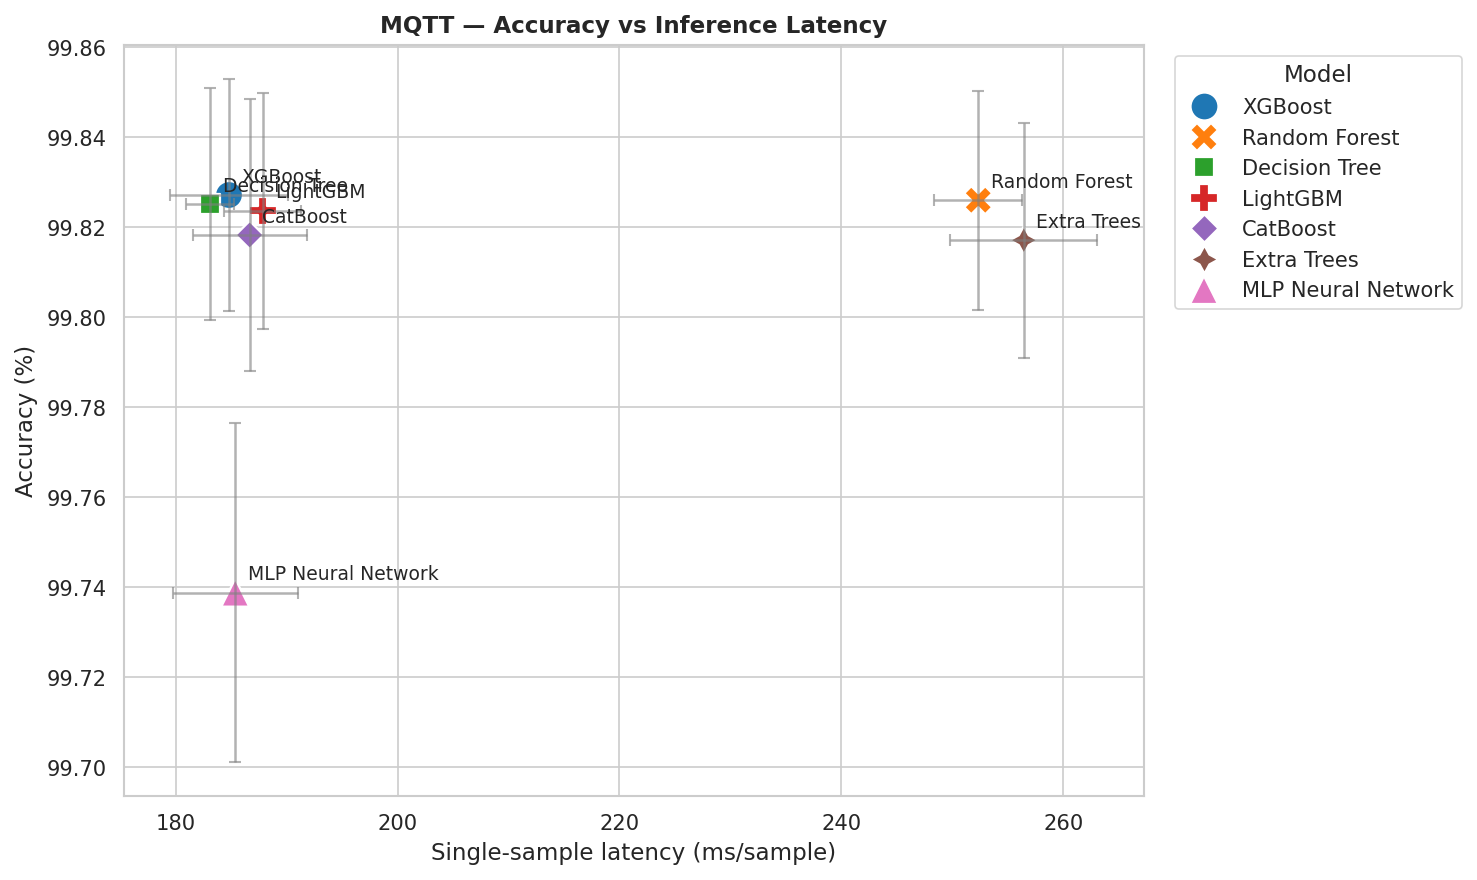

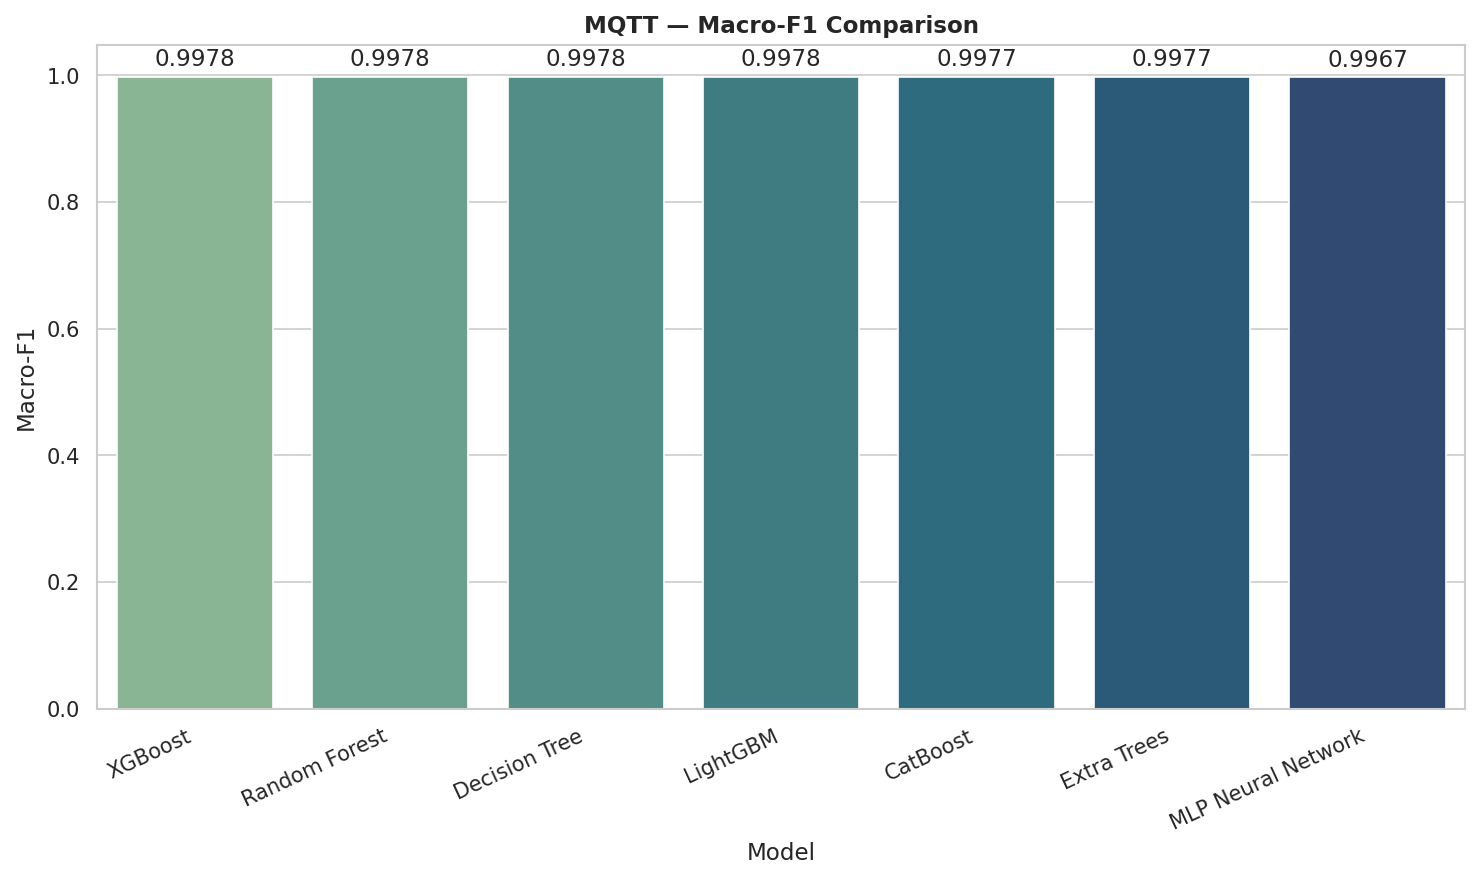

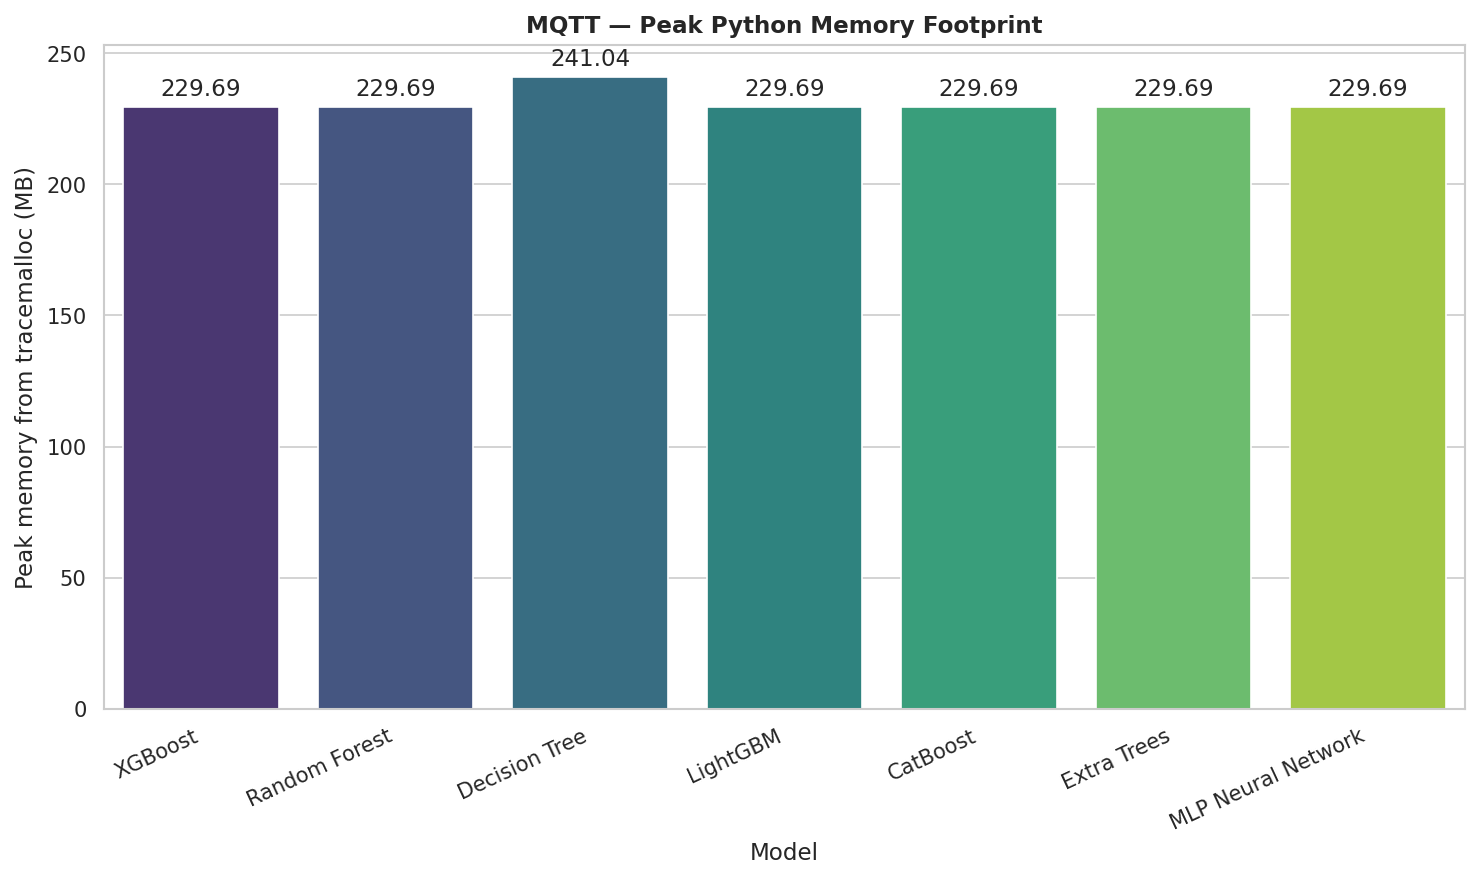

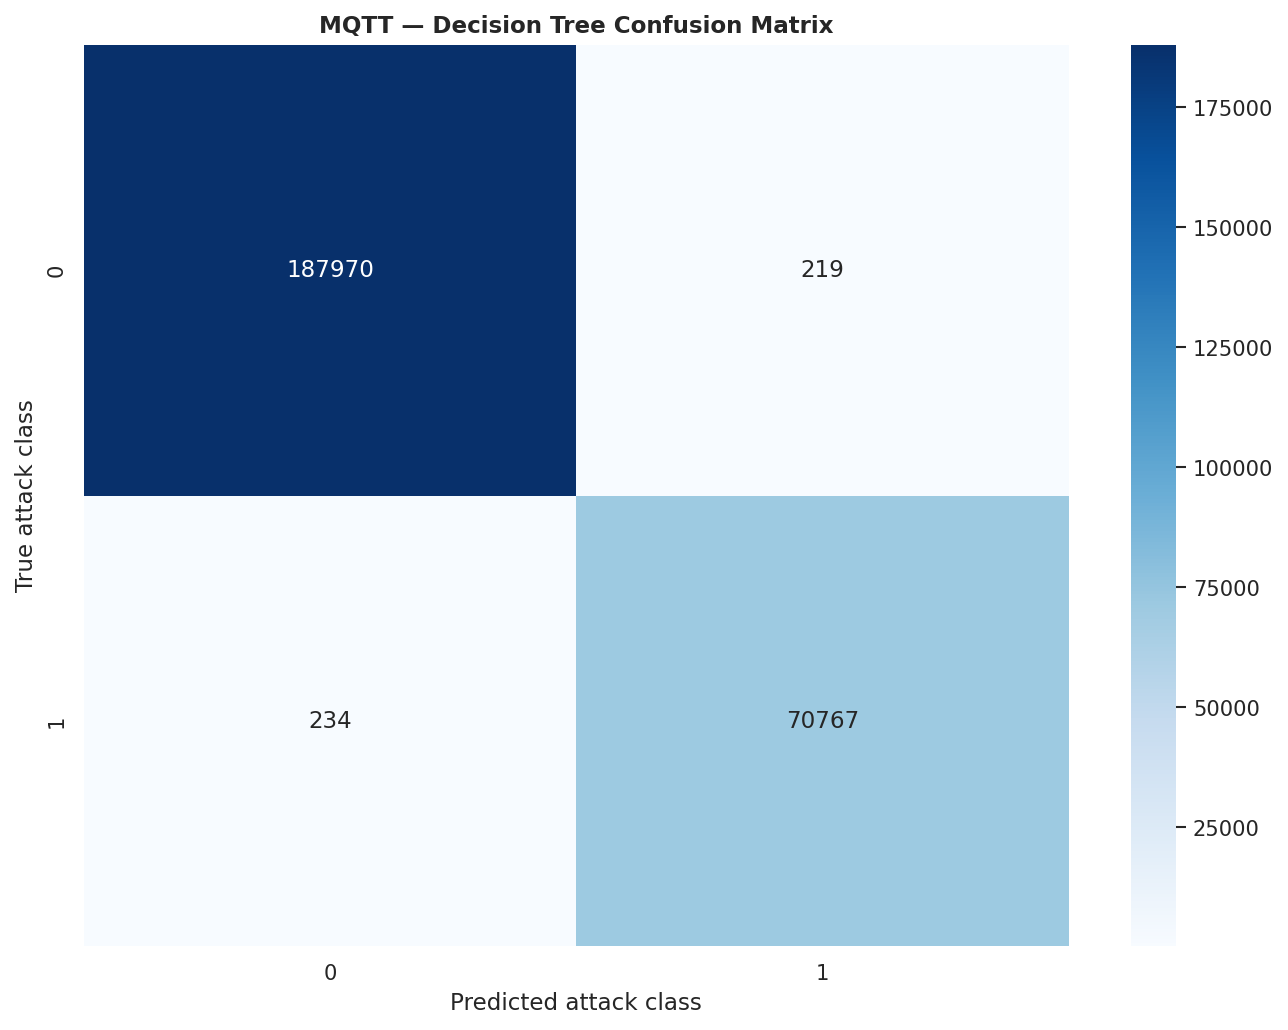

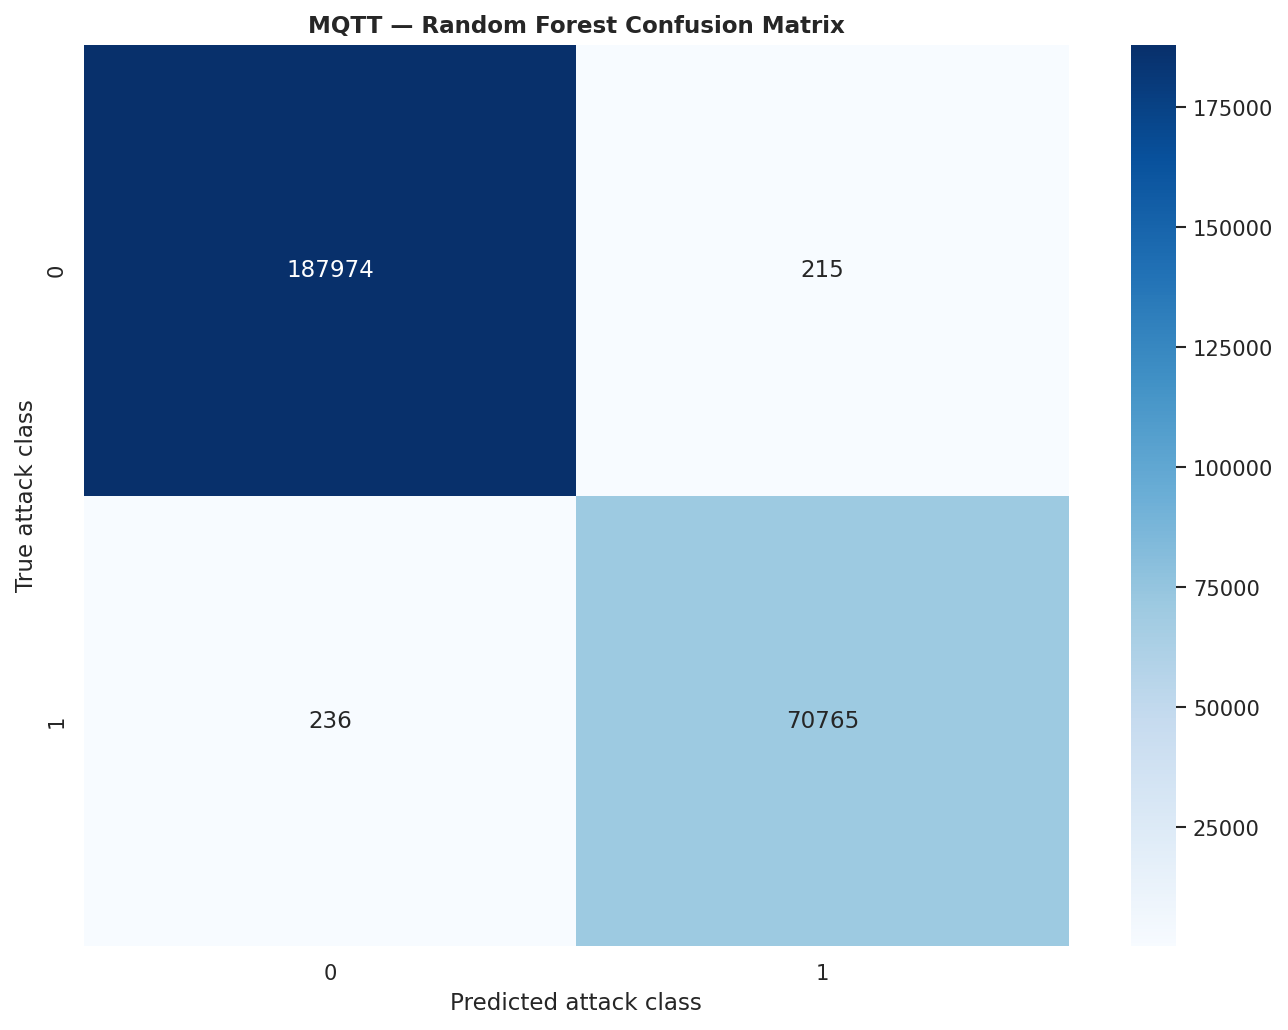

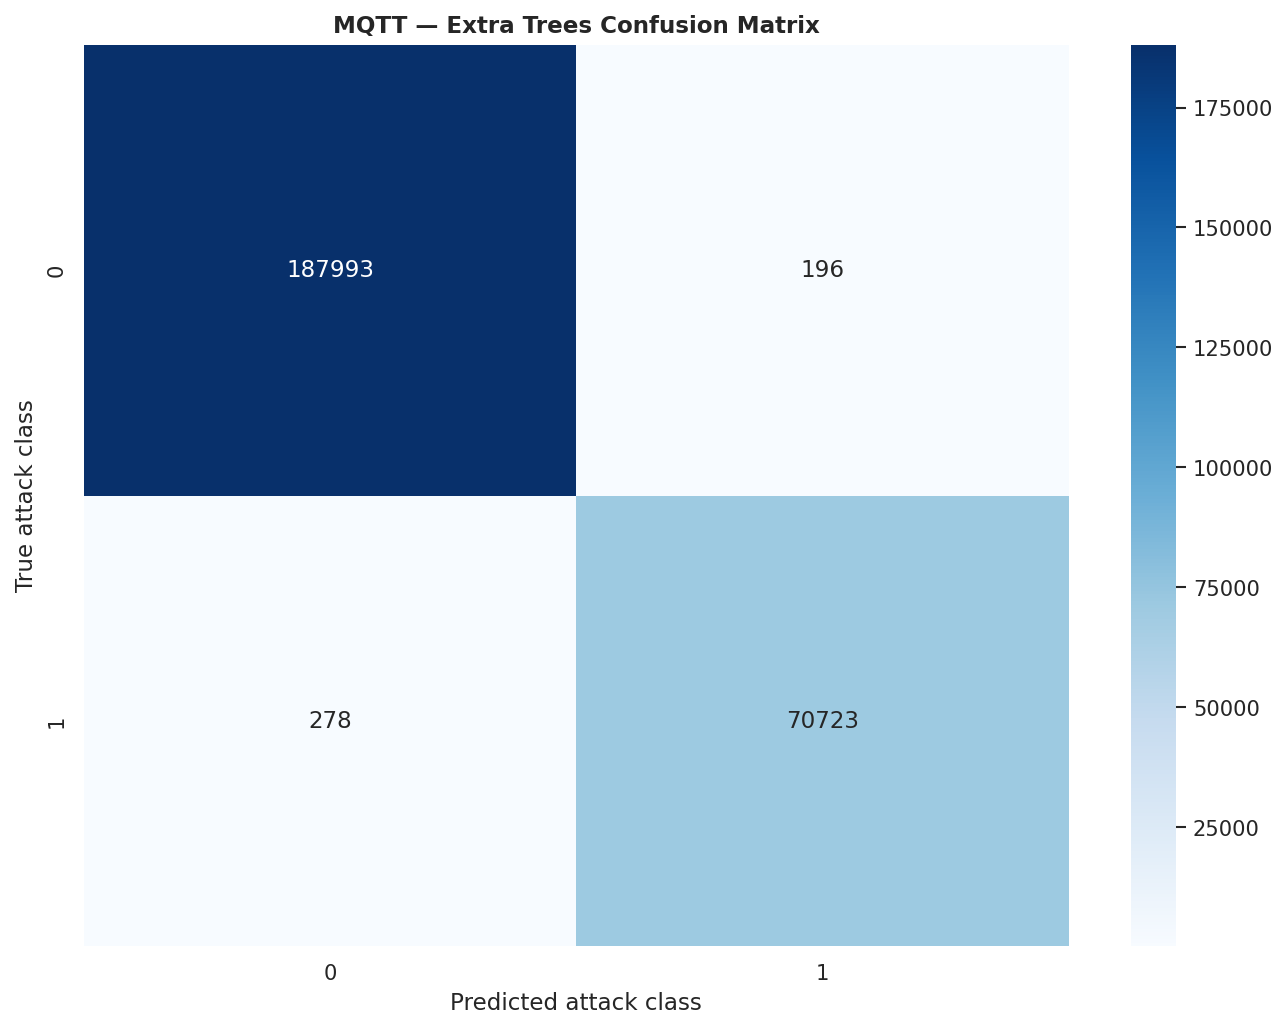

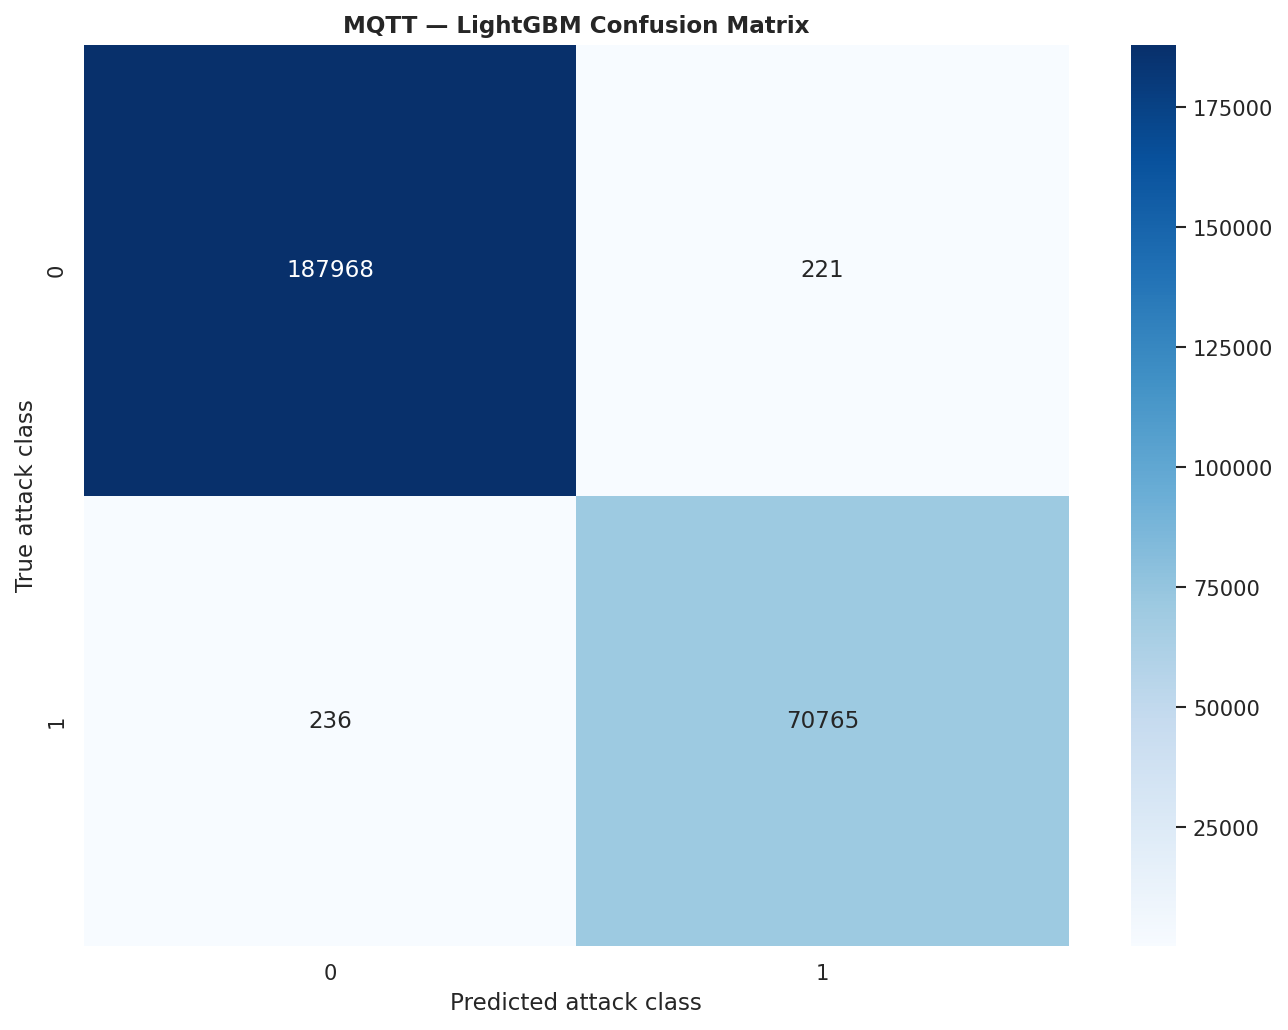

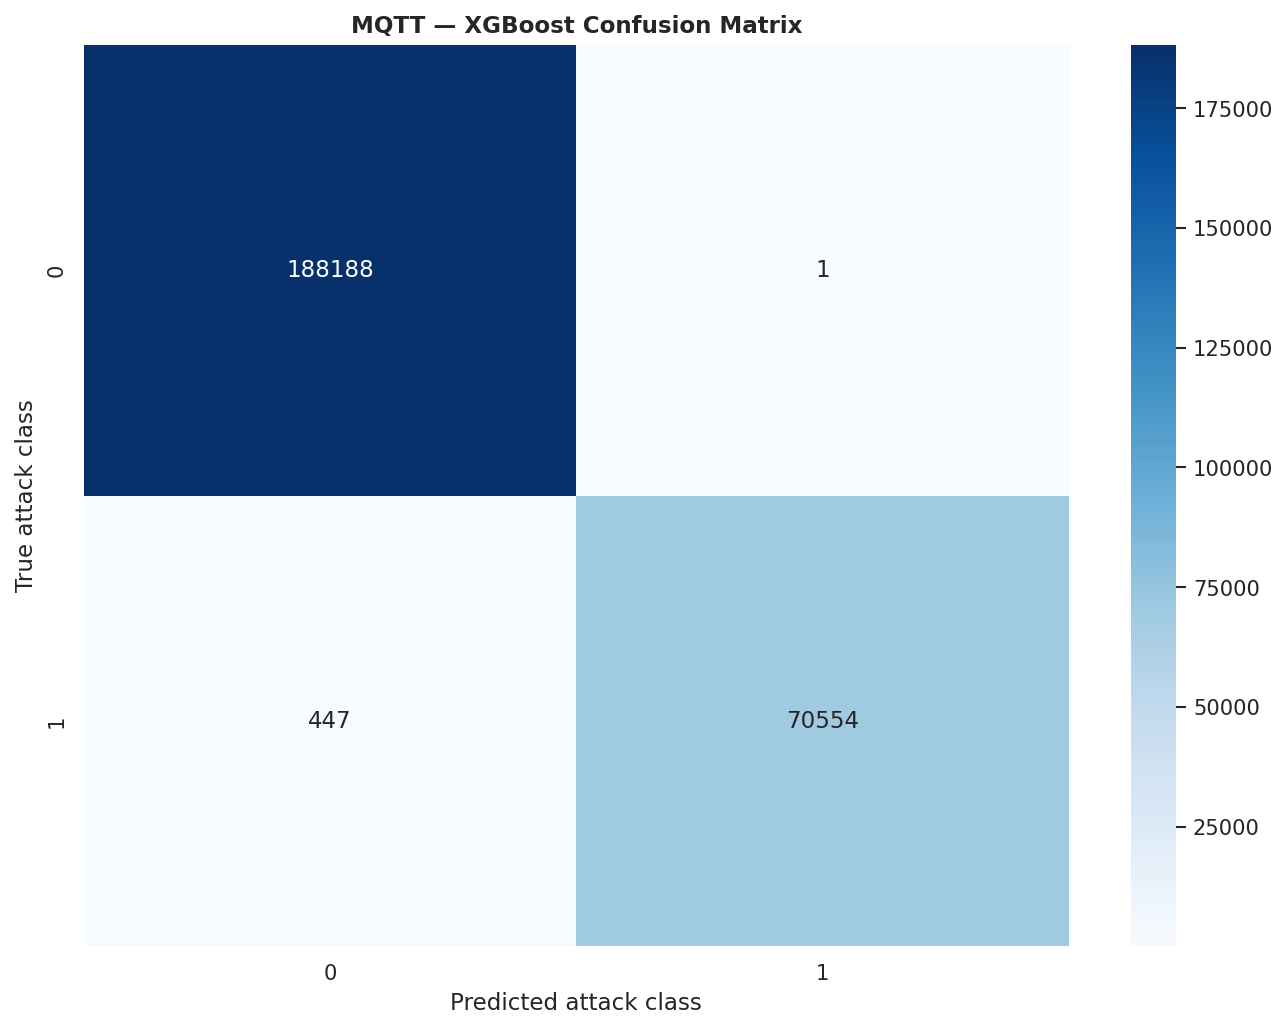

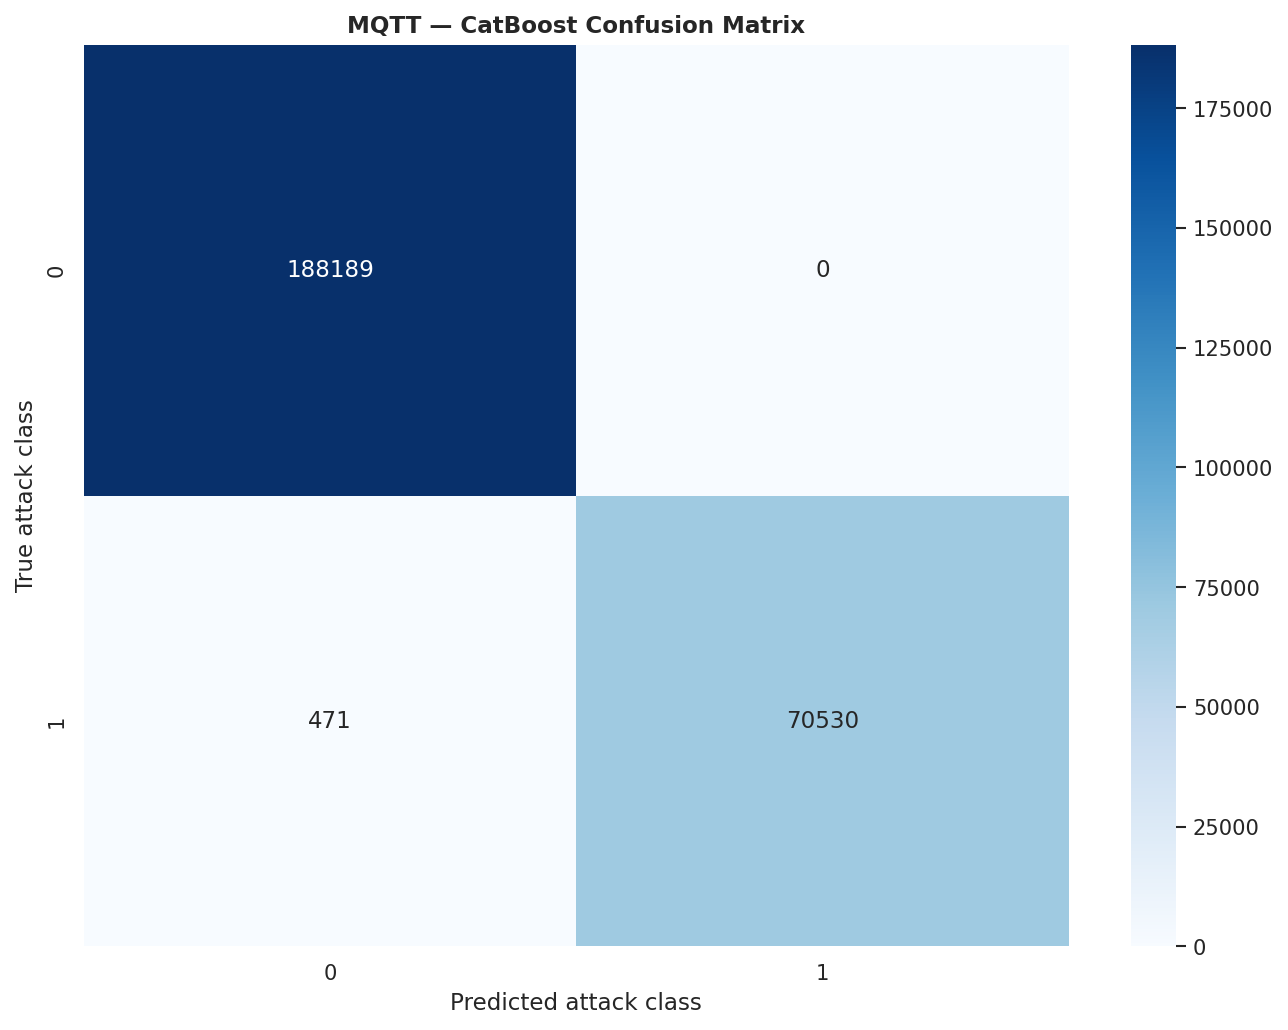

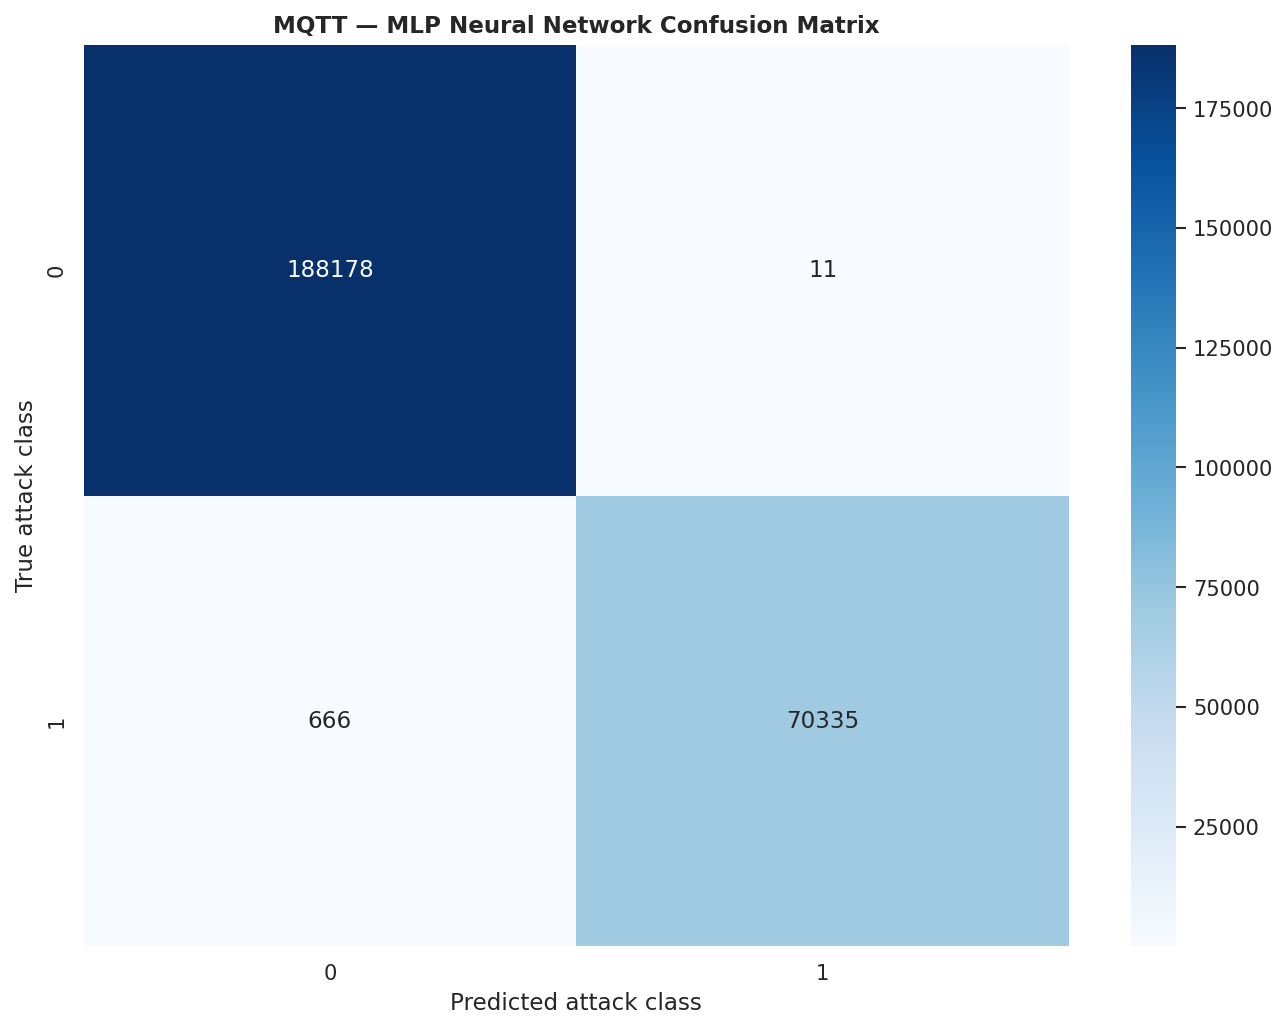

All figures saved at 300 DPI.


In [7]:
# Cell 4 — Publication-Quality Figures

sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.15
)

plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 300

output_prefix = DATASET_NAME

# Accuracy vs latency
plt.figure(
    figsize=(10, 6)
)

ax = sns.scatterplot(
    data=results_df,
    x="Latency Mean (ms/sample)",
    y="Accuracy Mean (%)",
    hue="Model",
    style="Model",
    s=180,
    palette="tab10"
)

for _, row in results_df.iterrows():

    ax.errorbar(
        row["Latency Mean (ms/sample)"],
        row["Accuracy Mean (%)"],
        xerr=row["Latency Std (ms/sample)"],
        yerr=row["Accuracy Std (%)"],
        fmt="none",
        ecolor="gray",
        alpha=0.6,
        capsize=3
    )

    ax.annotate(
        row["Model"],
        (
            row["Latency Mean (ms/sample)"],
            row["Accuracy Mean (%)"]
        ),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9
    )

plt.title(
    f"{DATASET_NAME.upper()} — Accuracy vs Inference Latency",
    fontweight="bold"
)

plt.xlabel(
    "Single-sample latency (ms/sample)"
)

plt.ylabel(
    "Accuracy (%)"
)

plt.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    f"{output_prefix}_accuracy_vs_latency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Macro-F1 comparison
plt.figure(
    figsize=(10, 6)
)

ax = sns.barplot(
    data=results_df,
    x="Model",
    y="Macro F1 Mean",
    hue="Model",
    palette="crest",
    legend=False
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f",
        padding=3
    )

plt.title(
    f"{DATASET_NAME.upper()} — Macro-F1 Comparison",
    fontweight="bold"
)

plt.xlabel("Model")
plt.ylabel("Macro-F1")

plt.xticks(
    rotation=25,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    f"{output_prefix}_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Peak Python memory comparison
plt.figure(
    figsize=(10, 6)
)

ax = sns.barplot(
    data=results_df,
    x="Model",
    y="RAM Footprint Mean (MB)",
    hue="Model",
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3
    )

plt.title(
    f"{DATASET_NAME.upper()} — Peak Python Memory Footprint",
    fontweight="bold"
)

plt.xlabel("Model")
plt.ylabel("Peak memory from tracemalloc (MB)")

plt.xticks(
    rotation=25,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    f"{output_prefix}_memory_usage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Confusion matrices
for model_name, matrix in (
    confusion_matrices.items()
):

    plt.figure(
        figsize=(9, 7)
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=target_encoder.classes_,
        yticklabels=target_encoder.classes_
    )

    plt.title(
        f"{DATASET_NAME.upper()} — "
        f"{model_name} Confusion Matrix",
        fontweight="bold"
    )

    plt.xlabel("Predicted attack class")
    plt.ylabel("True attack class")

    plt.tight_layout()

    safe_name = (
        model_name
        .replace(" ", "_")
        .replace("/", "_")
    )

    plt.savefig(
        f"{output_prefix}_{safe_name}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("All figures saved at 300 DPI.")

## Added: SHAP analysis and final CSV export

This cell fits the selected best tree model on the full cleaned dataset only for explanation, then exports SHAP and consolidated CSV files.


Best model for SHAP: XGBoost

Top SHAP features:


,Feature,Mean Absolute SHAP
4,bwd_min_pkt_len,3.127811
8,bwd_num_bytes,1.073167
1,fwd_mean_pkt_len,0.642875
5,fwd_max_pkt_len,0.568500
9,fwd_num_psh_flags,0.218675
2,bwd_mean_pkt_len,0.163285
7,fwd_num_bytes,0.086937
6,bwd_max_pkt_len,0.074241
0,fwd_num_pkts,0.018007
3,bwd_std_pkt_len,0.003236


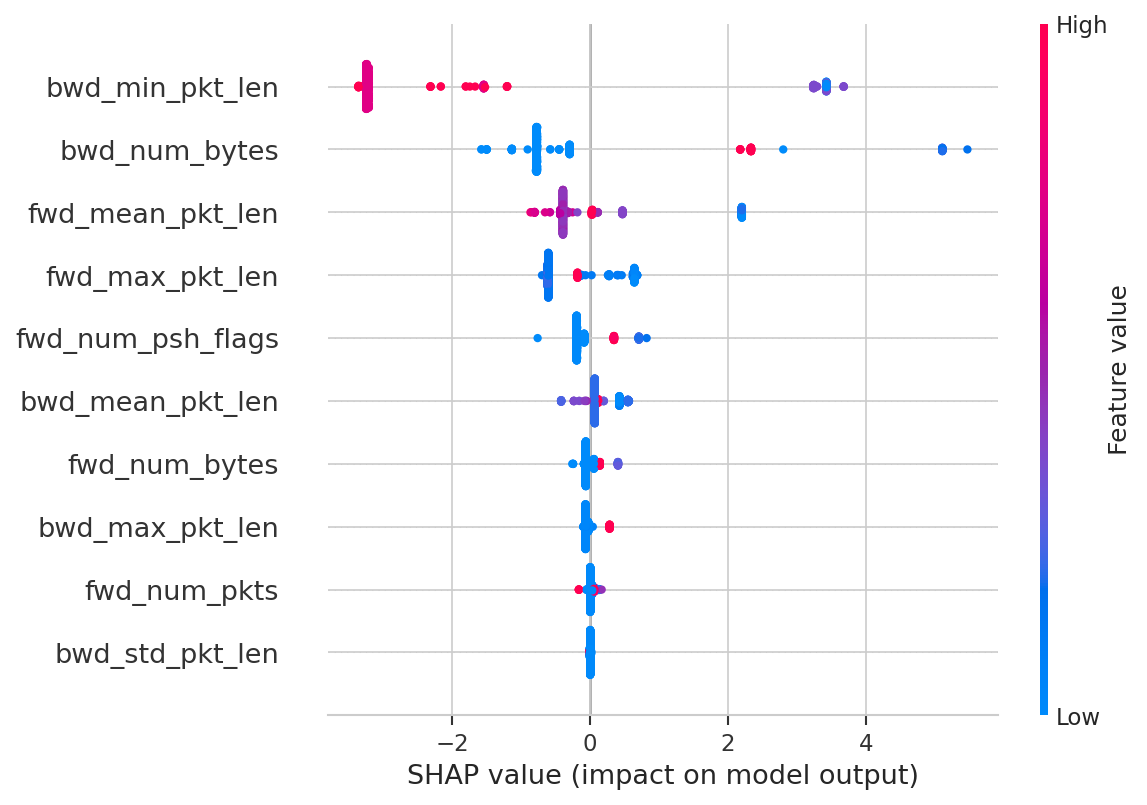


Final CSV files saved:
- mqtt_CatBoost_classification_report.csv
- mqtt_Decision_Tree_classification_report.csv
- mqtt_Extra_Trees_classification_report.csv
- mqtt_LightGBM_classification_report.csv
- mqtt_MLP_Neural_Network_classification_report.csv
- mqtt_Random_Forest_classification_report.csv
- mqtt_XGBoost_SHAP.csv
- mqtt_XGBoost_classification_report.csv
- mqtt_benchmark_summary.csv
- mqtt_fold_results.csv


In [8]:
# Added Cell - SHAP analysis and final CSV export

import shap
from pathlib import Path

# Consolidated CSV exports from the existing evaluation variables.
output_dir = Path(f"outputs_{DATASET_NAME}")
output_dir.mkdir(exist_ok=True)

fold_results_export = pd.DataFrame(fold_results)
summary_export = pd.DataFrame(summary_results)
fold_results_export.to_csv(output_dir / f"{DATASET_NAME}_fold_results.csv", index=False)
summary_export.to_csv(output_dir / f"{DATASET_NAME}_benchmark_summary.csv", index=False)

for report_model, report_table in classification_reports.items():
    safe_name = report_model.replace(" ", "_").replace("/", "_")
    report_table.to_csv(output_dir / f"{DATASET_NAME}_{safe_name}_classification_report.csv")

# Choose the best model using the existing summary metric.
best_model_name = (
    summary_export.sort_values("Macro F1 Mean", ascending=False).iloc[0]["Model"]
)
print("Best model for SHAP:", best_model_name)

best_pipeline = create_pipeline(
    clone(models[best_model_name])
)
best_pipeline.fit(X, y)

shap_sample = X.sample(min(500, len(X)), random_state=RANDOM_STATE)
preprocessor = best_pipeline.named_steps["preprocessor"]
selector = best_pipeline.named_steps["feature_selector"]
classifier = best_pipeline.named_steps["classifier"]
transformed_sample = preprocessor.transform(shap_sample)
selected_sample = selector.transform(transformed_sample)

explainer = shap.TreeExplainer(classifier)
shap_values = explainer.shap_values(selected_sample)
if isinstance(shap_values, list):
    shap_importance = np.mean(
        [np.abs(values).mean(axis=0) for values in shap_values], axis=0
    )
else:
    shap_array = np.asarray(shap_values)
    if shap_array.ndim == 2:
        shap_importance = np.abs(shap_array).mean(axis=0)
    else:
        shap_importance = np.abs(shap_array).mean(axis=(0, 2))

selected_names = preprocessor.get_feature_names_out()[selector.get_support()]
shap_results = pd.DataFrame({
    "Feature": selected_names,
    "Mean Absolute SHAP": shap_importance
}).sort_values("Mean Absolute SHAP", ascending=False)

shap_results.to_csv(
    output_dir / f"{DATASET_NAME}_{best_model_name.replace(' ', '_')}_SHAP.csv",
    index=False
)
print("\nTop SHAP features:")
display(shap_results.head(20))

# Publication-ready SHAP summary figure.
shap.summary_plot(
    shap_values,
    selected_sample,
    feature_names=selected_names,
    show=False
)
plt.tight_layout()
plt.savefig(
    output_dir / f"{DATASET_NAME}_{best_model_name.replace(' ', '_')}_SHAP_summary.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nFinal CSV files saved:")
for saved_file in sorted(output_dir.glob("*.csv")):
    print("-", saved_file.name)
